# Messi vs CR7 — Fase 2A: modelo de series temporales con decaimiento exponencial

**Requisito:** haber ejecutado `01_exploracion_datos.ipynb`. Este notebook lee la carpeta `data_limpia/` que crea ese notebook.

La pregunta que queremos responder es **a qué ritmo marca hoy cada jugador**. Con ese ritmo calculamos **cuándo llega a 1000**. Para estimar el ritmo actual combinamos tres ideas:

| Componente | Qué corrige |
|---|---|
| Ajuste por liga | Un gol en la Champions no vale lo mismo que un gol en la MLS |
| Peso por etapa | Los años de juvenil reflejan menos el nivel real del jugador |
| Decaimiento temporal | Lo de 2012 dice poco de cómo juega hoy un jugador de 39–41 años |

Ningún parámetro se elige "a ojo" si los datos pueden decidirlo: la vida media del decaimiento se calibra con un **backtest**.

In [16]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUTA = Path(r"C:\Users\DANIEL\OneDrive\Escritorio\Messi vs Cristiano")
DATA = RUTA / "data_limpia"

messi = pd.read_csv(DATA / "messi_goles_limpio.csv", parse_dates=["fecha"])
cr7 = pd.read_csv(DATA / "cr7_goles_club_limpio.csv", parse_dates=["fecha"])
por_anio = pd.read_csv(DATA / "goles_por_anio.csv")

NACIMIENTO = {"Messi": pd.Timestamp("1987-06-24"), "Ronaldo": pd.Timestamp("1985-02-05")}
CORTE      = {"Messi": messi.fecha.max(), "Ronaldo": pd.Timestamp("2026-08-20")}
TOTAL      = {"Messi": len(messi), "Ronaldo": int(por_anio.ronaldo.sum())}
CONTRATO   = {"Messi": pd.Timestamp("2028-12-31"), "Ronaldo": pd.Timestamp("2027-06-30")}
COLORES = {"Messi": "#2a78d6", "Ronaldo": "#eb6834"}

print(TOTAL)
print({j: str(f.date()) for j, f in CORTE.items()})

{'Messi': 930, 'Ronaldo': 977}
{'Messi': '2026-09-20', 'Ronaldo': '2026-08-20'}


`CONTRATO` guarda el fin del contrato actual de cada uno: Inter Miami hasta la temporada 2028 y Al-Nassr hasta mitad de 2027. Al final calculamos la probabilidad de que cada uno llegue a los 1000 **antes** de esa fecha.

## 1. Ajuste por calidad de liga

Cada gol se multiplica por un coeficiente que responde a esta pregunta: *¿a cuántos goles de una liga top europea equivale?* Una liga top europea vale 1.00.

Los valores son **supuestos explícitos**. El orden sigue el Opta Power Rankings, donde la MLS aparece por encima de la Saudi Pro League. Más abajo, el backtest dice si este ajuste mejora las predicciones o no.

Para asignar la categoría usamos reglas de texto con `np.select`: se evalúan en orden y **gana la primera que coincide**. Por eso `"afc champions"` va antes que `"champions league"`.

In [17]:
COEF = {
    "UCL": 1.10, "Mundial": 1.05, "Top liga europea": 1.00, "Serie A": 0.95,
    "Copa América / Euro": 0.95, "Ligue 1": 0.90, "Otros torneos UEFA/FIFA": 0.90,
    "Copas domésticas Europa": 0.85, "Eliminatorias": 0.85, "Liga Portugal": 0.80,
    "MLS": 0.70, "Torneos Concacaf": 0.70, "AFC Champions": 0.65, "Copas Portugal": 0.65,
    "Saudi Pro League": 0.62, "Copas Arabia": 0.60, "Amistosos": 0.60,
    "Sin detalle": 0.80,
}

REGLAS = [
    ("afc champions", "AFC Champions"),
    ("concacaf|leagues cup|campeones cup", "Torneos Concacaf"),
    ("champions league", "UCL"),
    ("qualification|eliminatorias", "Eliminatorias"),
    ("club world cup", "Otros torneos UEFA/FIFA"),
    ("world cup", "Mundial"),
    ("copa am", "Copa América / Euro"),
    ("amistoso", "Amistosos"),
    ("major league soccer", "MLS"),
    ("saudi pro", "Saudi Pro League"),
    ("king's cup|saudi super", "Copas Arabia"),
    ("laliga|la liga|premier league", "Top liga europea"),
    ("serie a", "Serie A"),
    ("ligue 1", "Ligue 1"),
    ("europa league|uefa (?:european )?super cup", "Otros torneos UEFA/FIFA"),
    ("liga portugal", "Liga Portugal"),
    ("taça", "Copas Portugal"),
    ("copa del rey|fa cup|efl cup|italy cup|supercop|super cup|troph", "Copas domésticas Europa"),
]

def categorizar(comp):
    s = comp.str.lower()
    return np.select([s.str.contains(rx) for rx, _ in REGLAS], [cat for _, cat in REGLAS], default="Sin detalle")


messi["cat"] = categorizar(messi.comp)
cr7["cat"] = categorizar(cr7.competition)
messi["coef"] = messi.cat.map(COEF)
cr7["coef"]   = cr7.cat.map(COEF)

assert (messi.cat != "Sin detalle").all() and (cr7.cat != "Sin detalle").all(), "hay competiciones sin regla"

todos = pd.concat([messi.assign(jug="Messi"), cr7.assign(jug="Ronaldo")], ignore_index=True)
tabla_cat = pd.crosstab(todos.cat, todos.jug)
tabla_cat.insert(0, "coef", tabla_cat.index.map(COEF))
tabla_cat.sort_values("coef", ascending=False)

jug,coef,Messi,Ronaldo
cat,,,
UCL,1.10,129,141
Mundial,1.05,21,0
Top liga europea,1.00,474,414
Serie A,0.95,0,81
Copa América / Euro,0.95,14,0
Otros torneos UEFA/FIFA,0.90,9,11
Ligue 1,0.90,22,0
Eliminatorias,0.85,36,0
Copas domésticas Europa,0.85,71,49


El `assert` está ahí por una razón práctica: si mañana actualizas el CSV y aparece una competición nueva, el notebook se detiene en vez de asignarle un coeficiente en silencio.

## 2. Tabla jugador-año

El modelo trabaja con **una fila por jugador y año calendario**:

- `goles`: goles reales (para Ronaldo salen del Excel, porque su CSV no incluye Portugal).
- `goles_aj`: goles × coeficiente. A los goles de Ronaldo que no están en su CSV (selección y los posteriores a febrero de 2026) se les asigna `"Sin detalle"` = 0.80.
- `expo` (exposición): fracción del año observada. 2026 no está completo, así que pesa menos como dato.
- `edad` y `etapa` se calculan en la mitad del periodo observado.

In [18]:
m_anio = messi.groupby("anio").agg(goles=("coef", "size"), goles_aj=("coef", "sum"))

r_csv = cr7.groupby("anio").agg(n_csv=("coef", "size"), aj_csv=("coef", "sum"))
r_anio = por_anio.set_index("anio")[["ronaldo"]].rename(columns={"ronaldo": "goles"}).join(r_csv).fillna(0)
r_anio["goles_aj"] = r_anio.aj_csv + (r_anio.goles - r_anio.n_csv) * COEF["Sin detalle"]

base = pd.concat([m_anio.assign(jugador="Messi"),
                  r_anio[["goles", "goles_aj"]].assign(jugador="Ronaldo")]).reset_index()

ini = pd.to_datetime(base.anio.astype(str) + "-01-01")
fin = pd.to_datetime(base.anio.astype(str) + "-12-31")
corte = base.jugador.map(CORTE)
base["fin"] = fin.where(fin < corte, corte)

base["expo"]  = base.fin.dt.dayofyear / np.where(ini.dt.is_leap_year, 366, 365)
base["mitad"] = ini + (base.fin - ini) / 2
base["edad"]  = (base.mitad - base.jugador.map(NACIMIENTO)).dt.days / 365.25
base["etapa"] = pd.cut(base.edad, [0, 22, 32, 99], right=False, labels=["Inicios", "Prime", "Transición"])
base["coef_mix"] = base.goles_aj / base.goles

base.groupby("jugador").tail(4)[["jugador", "anio", "goles", "goles_aj", "coef_mix", "expo", "edad", "etapa"]].round(3)

,jugador,anio,goles,goles_aj,coef_mix,expo,edad,etapa
18,Messi,2023,28,21.35,0.762,1.000,36.022,Transición
19,Messi,2024,29,20.80,0.717,1.000,37.021,Transición
20,Messi,2025,46,32.60,0.709,1.000,38.023,Transición
21,Messi,2026,34,26.40,0.776,0.721,38.883,Transición
43,Ronaldo,2023,54,36.43,0.675,1.000,38.401,Transición
44,Ronaldo,2024,43,28.05,0.652,1.000,39.400,Transición
45,Ronaldo,2025,41,26.96,0.658,1.000,40.402,Transición
46,Ronaldo,2026,20,14.56,0.728,0.636,41.218,Transición


`coef_mix` es el coeficiente promedio del año. Muestra con claridad el cambio de contexto: Messi pasa de ~0.97 en el Barça a ~0.71 en la MLS, y Ronaldo de ~0.95 en Europa a ~0.66 en Arabia.

## 3. Los pesos

**Peso por etapa** (Inicios < 22 años ≤ Prime < 32 años ≤ Transición):

In [19]:
PESO_ETAPA = {"Inicios": 0.6, "Prime": 1.0, "Transición": 0.9}
base["w_etapa"] = base.etapa.map(PESO_ETAPA).astype(float)

base.groupby(["jugador", "etapa"], observed=True).anio.agg(["min", "max", "count"])

min   max  count
jugador etapa                        
Messi   Inicios     2005  2008      4
        Prime       2009  2018     10
        Transición  2019  2026      8
Ronaldo Inicios     2002  2006      5
        Prime       2007  2016     10
        Transición  2017  2026     10

**Decaimiento temporal (time-decay):** un año que está a $\Delta t$ años de hoy pesa

$$w_{\text{decay}} = e^{-\ln 2 \,\cdot\, \Delta t / H} = 2^{-\Delta t / H}$$

$H$ es la **vida media**: cada $H$ años el peso se reduce a la mitad. El dato más reciente pesa casi 1 y los antiguos tienden a 0.

El peso final de cada año es $w = w_{\text{etapa}} \times w_{\text{decay}}$.

### Tasa ponderada

Con los pesos, la tasa actual de goles (ajustados) por año es:

$$\hat\lambda = \frac{\sum_t w_t \cdot \text{goles\_aj}_t}{\sum_t w_t \cdot \text{expo}_t}$$

No es un promedio simple de tasas. Es el **estimador de máxima verosimilitud de un Poisson ponderado**: los años incompletos aportan en proporción a su exposición.

Para volver a goles **reales** se divide entre el coeficiente del contexto donde jugará: $\lambda_{\text{real}} = \hat\lambda / c_{\text{futuro}}$. Este paso es clave. Si no se "des-ajusta", el modelo proyectaría goles de liga europea para alguien que juega en la MLS.

In [20]:
def decay(dt, H):
    return np.exp(-np.log(2) * dt / H)


def tasa_ajustada(hist, ref, H, gamma=1.0):
    dt = (ref - hist.mitad).dt.days / 365.25
    w = hist.w_etapa * decay(dt, H)
    g_aj = hist.goles * hist.coef_mix**gamma
    return (w * g_aj).sum() / (w * hist.expo).sum()

## 4. Calibración con backtest

Usamos el pasado para elegir $H$. Para cada año $Y$ entre 2012 y 2026:
1. nos ubicamos el 1 de enero de $Y$ y usamos **solo** los datos anteriores,
2. estimamos la tasa y predecimos los goles de $Y$,
3. comparamos contra lo que realmente pasó.

El parámetro `gamma` controla **cuánto** se aplica el ajuste por liga: 0 = nada, 1 = completo. Así comprobamos si el ajuste ayuda de verdad. Para el año que se predice usamos el `coef_mix` real, porque cuando arranca el año el traspaso ya ocurrió y se sabe en qué liga jugará.

La métrica es la **devianza de Poisson**, la medida natural de error para conteos. Menor es mejor.

In [21]:
def backtest(H, gamma, desde=2012):
    filas = []
    for jug, sub in base.groupby("jugador"):
        for Y in range(desde, 2027):
            hist, obj = sub[sub.anio < Y], sub[sub.anio == Y].iloc[0]
            lam = tasa_ajustada(hist, pd.Timestamp(f"{Y}-01-01"), H, gamma)
            filas.append((jug, Y, obj.goles, lam / obj.coef_mix**gamma * obj.expo))
    return pd.DataFrame(filas, columns=["jugador", "anio", "real", "pred"])


def devianza(bt):
    y, mu = bt.real, bt.pred
    return 2 * (y * np.log(y / mu) - (y - mu)).sum()


grid = pd.DataFrame([(H, g, devianza(backtest(H, g)))
                     for H in [0.5, 0.75, 1, 1.5, 2, 3, 5]
                     for g in [0, 0.5, 1]], columns=["H", "gamma", "dev"])

grid.pivot(index="H", columns="gamma", values="dev").round(1)

gamma,0.0,0.5,1.0
H,,,
0.50,130.2,122.1,117.5
0.75,118.3,112.5,110.9
1.00,115.1,111.3,112.7
1.50,118.2,118.4,126.1
2.00,125.1,129.3,143.1
3.00,138.8,149.3,172.6
5.00,156.8,173.3,206.0


In [22]:
mejor = grid.loc[grid.dev.idxmin()]
H, GAMMA = float(mejor.H), float(mejor.gamma)
print(f"Vida media óptima: {H} años | gamma: {GAMMA} | devianza: {mejor.dev:.1f}")

sin_ajuste = grid.query("H == @H and gamma == 0").dev.iloc[0]
print(f"El ajuste por liga reduce el error {1 - mejor.dev / sin_ajuste:.1%} frente a no ajustar")

Vida media óptima: 0.75 años | gamma: 1.0 | devianza: 110.9
El ajuste por liga reduce el error 6.2% frente a no ajustar


Cómo leer la tabla:
- **Memoria corta.** Las vidas medias cortas ganan por mucho: lo que ocurrió hace más de 2–3 años casi no ayuda a predecir el próximo año.
- **El ajuste por liga aporta.** Con `gamma = 1` el error baja frente a `gamma = 0`, así que los coeficientes contienen información real.

Veamos el detalle de los últimos años con los parámetros ganadores:

In [23]:
bt = backtest(H, GAMMA)
bt["error"] = bt.real - bt.pred

print("Sesgo medio (real - pred):", round(bt.error.mean(), 2), "goles/año")
bt[bt.anio >= 2019].pivot(index="anio", columns="jugador", values=["real", "pred"]).round(1)

Sesgo medio (real - pred): -2.86 goles/año


real          pred        
jugador Messi Ronaldo Messi Ronaldo
anio                               
2019     50.0    39.0  53.2    54.5
2020     27.0    44.0  50.4    43.5
2021     43.0    47.0  36.9    45.0
2022     35.0    16.0  46.1    45.2
2023     28.0    54.0  44.7    38.9
2024     29.0    43.0  36.8    49.6
2025     46.0    41.0  32.5    45.3
2026     34.0    20.0  26.7    24.5

El sesgo es **negativo**: el modelo tiende a sobreestimar. Tiene sentido, porque una media ponderada no sabe que los jugadores envejecen y siempre va un paso atrás de la caída. Esa es la motivación del modelo bayesiano (Fase 2B), que añade un término de edad.

## 5. Pesos finales (vistos desde la fecha de corte)

In [24]:
dt_hoy = (base.jugador.map(CORTE) - base.mitad).dt.days / 365.25
base["w"] = base.w_etapa * decay(dt_hoy, H)

n_ef = base.groupby("jugador").w.apply(lambda w: w.sum()**2 / (w**2).sum())
print("Años efectivos de información:", n_ef.round(2).to_dict())

base.pivot(index="anio", columns="jugador", values="w").tail(6).round(3)

Años efectivos de información: {'Messi': 2.46, 'Ronaldo': 2.51}


jugador,Messi,Ronaldo
anio,,
2021,0.007,0.008
2022,0.018,0.020
2023,0.046,0.050
2024,0.116,0.125
2025,0.292,0.316
2026,0.646,0.673


**Años efectivos** $= (\sum w)^2 / \sum w^2$. Con estos pesos, toda la carrera "vale" lo mismo que ~2.5 años de datos sin ponderar. Esto es lo que significa, en la práctica, darle prioridad al rendimiento actual.

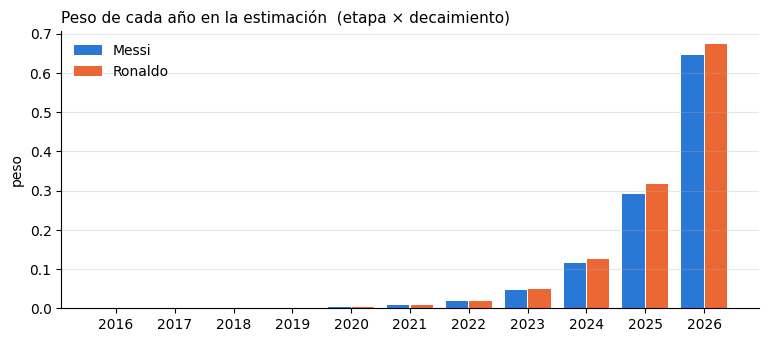

In [25]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (jug, sub) in enumerate(base[base.anio >= 2016].groupby("jugador")):
    ax.bar(sub.anio + (i - 0.5) * 0.4, sub.w, width=0.38, color=COLORES[jug], label=jug)

ax.set_title("Peso de cada año en la estimación  (etapa × decaimiento)", loc="left", fontsize=11)
ax.set_ylabel("peso")
ax.set_xticks(range(2016, 2027))
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## 6. Modelo A: proyección a 1000 goles

$c_{\text{futuro}}$ es el coeficiente medio de los dos últimos años: describe en qué contexto competitivo juega hoy cada uno.

Para el **tiempo de llegada** usamos una propiedad del proceso de Poisson. Si un jugador marca a ritmo $\lambda$ goles/año, el tiempo hasta su gol número $n$ sigue una distribución **Gamma**:

$$T_n \sim \text{Gamma}(n,\ \lambda) \qquad E[T_n] = n/\lambda$$

Así no hace falta simular partido a partido: sacamos 100 000 tiempos de una Gamma y obtenemos fechas, intervalos y la probabilidad de que cada uno llegue primero.

In [26]:
rng = np.random.default_rng(42)
N_SIM = 100_000
llegadas_a, filas = {}, []

for jug, sub in base.groupby("jugador"):
    lam_aj = tasa_ajustada(sub, CORTE[jug], H, GAMMA)
    rec = sub[sub.anio >= sub.anio.max() - 1]
    c_fut = (rec.goles * rec.coef_mix**GAMMA).sum() / rec.goles.sum()
    lam = lam_aj / c_fut
    faltan = 1000 - TOTAL[jug]

    t = rng.gamma(shape=faltan, scale=1 / lam, size=N_SIM)
    f = pd.Series(CORTE[jug] + pd.to_timedelta(t * 365.25, unit="D"))
    llegadas_a[jug] = f

    filas.append({"jugador": jug, "tasa_aj": lam_aj, "c_futuro": c_fut, "goles_por_año": lam,
                  "faltan": faltan, "p10": f.quantile(.1).date(), "mediana": f.quantile(.5).date(), "p90": f.quantile(.9).date(),
                  "P_antes_fin_contrato": (f < CONTRATO[jug]).mean()})

res_a = pd.DataFrame(filas).set_index("jugador")
res_a.round(3)

,tasa_aj,c_futuro,goles_por_año,faltan,p10,mediana,p90,P_antes_fin_contrato
jugador,,,,,,,,
Messi,32.642,0.738,44.261,70,2028-01-23,2028-04-16,2028-07-19,0.999
Ronaldo,25.751,0.681,37.832,23,2027-02-01,2027-03-27,2027-05-29,0.967


In [27]:
p_cr7 = (llegadas_a["Ronaldo"].values < llegadas_a["Messi"].values).mean()
print(f"P(Ronaldo llega primero) = {p_cr7:.2%}")

for jug, r in res_a.iterrows():
    print(f"{jug:<8} {r.goles_por_año:5.1f} goles/año -> 1000 el {r.mediana:%d-%b-%Y}"
          f"  (80%: {r.p10:%b-%Y} a {r.p90:%b-%Y})  | P(antes de fin de contrato) = {r.P_antes_fin_contrato:.0%}")

P(Ronaldo llega primero) = 100.00%
Messi     44.3 goles/año -> 1000 el 16-Apr-2028  (80%: Jan-2028 a Jul-2028)  | P(antes de fin de contrato) = 100%
Ronaldo   37.8 goles/año -> 1000 el 27-Mar-2027  (80%: Feb-2027 a May-2027)  | P(antes de fin de contrato) = 97%


Con estos supuestos Ronaldo llega primero prácticamente siempre: necesita 23 goles y Messi 70. Ojo, ese ~100% está **sobreconfiado**. Solo incluye el azar del Poisson (cuántos goles caen en cada semana) y trata la tasa como si se conociera con exactitud. Le faltan dos fuentes de incertidumbre:
1. **No sabemos la tasa real**: con ~2.5 años efectivos de datos hay un margen de error. El modelo bayesiano lo incorpora.
2. **El envejecimiento**: el backtest mostró que este modelo sobreestima. El modelo bayesiano añade una pendiente por edad.

Fíjate en `P_antes_fin_contrato` de Ronaldo: entre su fecha estimada y el fin de su contrato con Al-Nassr (junio 2027) hay apenas unos meses de margen. En la Fase 2B veremos cuánto cambia esa probabilidad cuando se incluye la incertidumbre completa.

## 7. Validación contra datos reales posteriores al corte

Nuestros datos terminan en agosto/septiembre. Según messivsronaldo.football, al 17-oct-2026 Messi tenía 932 goles y Ronaldo 981. El modelo **no vio** esos goles, así que sirven como prueba fuera de muestra (pequeña).

In [28]:
REF_WEB, F_WEB = {"Messi": 932, "Ronaldo": 981}, pd.Timestamp("2026-10-17")

val = res_a[["goles_por_año"]].copy()
val["dias"] = [(F_WEB - CORTE[j]).days for j in val.index]
val["esperados"] = val.goles_por_año * val.dias / 365.25
val["reales"] = [REF_WEB[j] - TOTAL[j] for j in val.index]
val["rango_90%"] = [tuple(np.percentile(rng.poisson(mu, 50_000), [5, 95]).astype(int)) for mu in val.esperados]
val.round(1)

,goles_por_año,dias,esperados,reales,rango_90%
jugador,,,,,
Messi,44.3,27,3.3,2,"(1, 6)"
Ronaldo,37.8,58,6.0,4,"(2, 10)"


Si los goles reales caen dentro del rango del 90%, el modelo es coherente con lo que pasó después. Con tan pocos días es una prueba débil, pero es honesta.

## 8. Curva de proyección

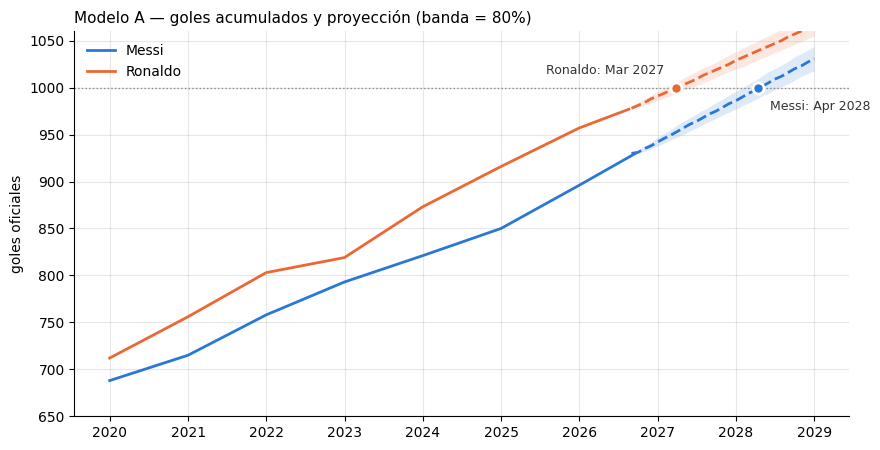

In [29]:
meses = pd.date_range("2026-09-01", "2029-01-01", freq="MS")
fig, ax = plt.subplots(figsize=(10, 5))

for jug, sub in base.groupby("jugador"):
    hist = sub[sub.anio >= 2019]
    ax.plot(hist.fin, sub.goles.cumsum()[sub.anio >= 2019], color=COLORES[jug], lw=2, label=jug)

    t = np.clip((meses - CORTE[jug]).days / 365.25, 0, None)
    sims = TOTAL[jug] + rng.poisson(res_a.loc[jug, "goles_por_año"] * t, size=(5000, len(t)))
    p10, p50, p90 = np.percentile(sims, [10, 50, 90], axis=0)
    ax.fill_between(meses, p10, p90, color=COLORES[jug], alpha=0.15, lw=0)
    ax.plot(meses, p50, color=COLORES[jug], lw=2, ls="--")

    med = res_a.loc[jug, "mediana"]
    ax.plot(med, 1000, "o", ms=8, color=COLORES[jug], mec="white", mew=2, zorder=5)
    izq = jug == "Ronaldo"
    ax.annotate(f"{jug}: {med:%b %Y}", (med, 1000), xytext=(-8 if izq else 8, 10 if izq else -16),
                textcoords="offset points", ha="right" if izq else "left", fontsize=9, color="#333")

ax.axhline(1000, color="#888", lw=1, ls=":")
ax.set_ylim(650, 1060)
ax.set_title("Modelo A — goles acumulados y proyección (banda = 80%)", loc="left", fontsize=11)
ax.set_ylabel("goles oficiales")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

## 9. Guardar para la Fase 2B y el dashboard

In [30]:
cols = ["jugador", "anio", "goles", "goles_aj", "coef_mix", "expo", "mitad", "fin", "edad", "etapa", "w_etapa", "w"]
base[cols].to_csv(DATA / "modelo_base.csv", index=False)

params = {
    "H": H, "gamma": GAMMA, "peso_etapa": PESO_ETAPA, "coef_liga": COEF,
    "total": TOTAL,
    "corte": {j: str(f.date()) for j, f in CORTE.items()},
    "nacimiento": {j: str(f.date()) for j, f in NACIMIENTO.items()},
    "contrato": {j: str(f.date()) for j, f in CONTRATO.items()},
    "c_futuro": res_a.c_futuro.round(4).to_dict(),
}
(DATA / "parametros_modelo.json").write_text(json.dumps(params, indent=2, ensure_ascii=False), encoding="utf-8")
res_a.to_csv(DATA / "resultados_modelo_a.csv")

sorted(p.name for p in DATA.iterdir())

['cr7_goles_club_limpio.csv',
 'goles_por_anio.csv',
 'llegadas_bayes.csv',
 'messi_goles_limpio.csv',
 'modelo_base.csv',
 'parametros_modelo.json',
 'partidos.csv',
 'proyeccion_bayes.csv',
 'resultados_modelo_a.csv',
 'resultados_modelo_b.csv',
 'resumen_totales.csv']